# Running ELAsTiCC light curves through SELDON with Hyrax on DeltaAI

This notebook runs the [ELAsTiCC2](https://portal.nersc.gov/cfs/lsst/DESC_TD_PUBLIC/ELASTICC/)
training light curves through a trained SELDON model, using Hyrax's `infer` verb and
`hyrax_seldon`'s model (`HyraxSeldon`) and dataset (`ElasticcParquetDataset`), on one GPU of
NCSA's [DeltaAI](https://docs.ncsa.illinois.edu/systems/deltaai/en/latest/index.html).

It is self-contained: the setup steps you do once on DeltaAI are in this first part, as shell
commands to run in a DeltaAI terminal. The code cells after that run on a GPU node.

What it does:

1. Selects the ELAsTiCC objects SELDON can use (all of them by default, or a fixed number per
   class) from the parquet files that `data/download_elasticc.py` makes, and writes them to one
   parquet file.
2. Runs `h.infer()` with `HyraxSeldon` loaded from a SELDON training run's Lightning checkpoint.
3. Reads the results back and checks them: against the data, against the true ELAsTiCC classes,
   and against SELDON run directly, without Hyrax.

On the whole training set (about 1.5 million objects, 289,245 of which SELDON can use) the
notebook takes about 8 minutes, under 6 of them in Hyrax's inference (about 340 s, or 850 objects/s, including compiling SELDON) on one GPU. Nothing in it needs more than one GPU.

## Part 1: One-time setup on DeltaAI

Run these in a terminal on a DeltaAI login node (`ssh <username>@dtai-login.delta.ncsa.illinois.edu`).
The login nodes are shared: use them for installing software and moving files, and leave
model runs to the GPU nodes (part 2).

### 1a. Pick an allocation and a place for large files

```bash
accounts                         # your DeltaAI accounts, e.g. bgud-dtai-gh: this is the Slurm --account
quota                            # your home quota (~100 GB) and your allocations' /projects and /work space
```

Your home directory is small, so put the data (7.4 GiB download, 8 GB extracted, 6.4 GB of
parquet) in your allocation's project space, for example `/projects/<allocation>/$USER`. Below,
`<allocation>` is the short name of your account (`bgud` for `bgud-dtai-gh`).

### 1b. A Python environment with hyrax_seldon

DeltaAI's nodes are aarch64 (NVIDIA Grace Hopper). A conda-forge Miniconda/Miniforge plus pip
works; the PyPI `torch` wheels for aarch64 include CUDA.

```bash
# Miniforge (conda-forge only) in your home directory, if you don't have conda already
curl -LO https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-aarch64.sh
bash Miniforge3-Linux-aarch64.sh -b -p ~/miniforge3
source ~/miniforge3/etc/profile.d/conda.sh

conda create -y -n hyrax-seldon python=3.12
conda activate hyrax-seldon

git clone https://github.com/lincc-frameworks/hyrax_seldon.git
pip install -e './hyrax_seldon[dev]'   # pulls in hyrax, hyrax_alerts, SELDON (seldon_core), torch
pip install ipykernel matplotlib

# Make the environment a Jupyter kernel, so Open OnDemand's JupyterLab can use it
python -m ipykernel install --user --name hyrax-seldon --display-name "hyrax-seldon"
```

`hyrax_seldon` needs a `hyrax` with `[model].parallel_prepare_inputs`, which is not in a release
yet; its dependencies install `hyrax` from the `mtauraso-parallel-prepare-inputs` branch on GitHub.

If you already have editable checkouts of `hyrax`, `hyrax_alerts` and SELDON in the environment,
install `hyrax_seldon` with `pip install --no-deps -e ./hyrax_seldon` so its git dependencies don't
replace them, and check out `hyrax`'s `mtauraso-parallel-prepare-inputs` branch.

### 1c. The SELDON checkpoint

The model is a SELDON training run (`SELDONEnergyClassifierDictModel`). Unpack the run you were
given, e.g. the SELDON 2.0 `..._roman_elasticc` tarball, anywhere; what matters is the run
directory, which holds:

```
<run_dir>/hparams.yaml                 # the run config: architecture, preprocessing, statistics, classes
<run_dir>/checkpoints/<name>.ckpt      # the Lightning checkpoint
```

Use it as it is. `hparams.yaml` holds absolute paths from the machine SELDON was trained on
(for the filter transmission curves); `hyrax_seldon` points them at the copies installed with
SELDON, so the file does not need editing.

### 1d. Download and convert ELAsTiCC2 (once)

`hyrax_seldon` has a script that downloads the ELAsTiCC2 training sample (7.4 GiB), extracts it
and converts it to the parquet schema SELDON reads, one file per class:

```bash
python hyrax_seldon/data/download_elasticc.py \
    --data-dir /projects/<allocation>/$USER/elasticc2_train --workers 4
```

The download and extraction take about 10 minutes and are file handling, fine on a login node.
Converting all 40 FITS files of each class is heavier; on a login node keep `--workers` small,
or run the same command in a CPU-rich job (with `--workers 32` it took under a minute on a
DeltaAI node). The script is safe to rerun: finished steps are skipped. The output is
`/projects/<allocation>/$USER/elasticc2_train/parquet/<class>.parquet`.

For a quick look, `--files-per-class 1` converts only the first file of each class (about 40,000
objects in all) into `parquet_1_files_per_class/`; point `ELASTICC_PARQUET_DIR` below at it.

## Part 2: Run this notebook on one GPU

Either way below, you get one GH200 GPU on a `ghx4` node. `HyraxSeldon` prepares each batch with SELDON's preprocessing in the data loader's worker processes (`[model].parallel_prepare_inputs`, on by default), while the GPU runs SELDON on earlier batches; the timings here use 8 workers, which the 16 CPUs below leave room for. `HyraxSeldon` runs SELDON compiled with `torch.compile`, which builds some of its code with the C++ compiler named by `CXX`; DeltaAI sets `CXX` to the Cray `CC` wrapper, which torch cannot use, so the settings cell below points it at `g++`. The `ghx4` partition is charged at
1x; `ghx4-interactive` is charged at 2x and limited to 2 hours, but often starts sooner.

**Option A: JupyterLab in Open OnDemand.** Go to <https://gh-ondemand.delta.ncsa.illinois.edu/>,
choose *Interactive Apps → Jupyter Lab*, and fill in the form:

| Field | Value |
|---|---|
| Name of account | your account from `accounts`, e.g. `bgud-dtai-gh` |
| Partition | `ghx4` |
| Duration of job | `00:30:00` |
| Number of CPUs | `16` |
| Amount of RAM | `64g` |
| Number of GPUs | `1` |

When the session starts, open this notebook, choose the **hyrax-seldon** kernel, edit the
settings cell below, and run all cells. End the session from *My Interactive Sessions* when
you are done, so the GPU stops being charged.

**Option B: a batch job.** Save this as `run_notebook.sbatch` next to the notebook, edit the
account and the conda lines, and `sbatch run_notebook.sbatch`. The executed notebook, with its
outputs, replaces the original.

```bash
#!/bin/bash
#SBATCH --account=bgud-dtai-gh
#SBATCH --partition=ghx4
#SBATCH --nodes=1
#SBATCH --ntasks-per-node=1
#SBATCH --cpus-per-task=16
#SBATCH --mem=64g
#SBATCH --gpus-per-node=1
#SBATCH --time=00:30:00
#SBATCH --job-name=elasticc-seldon
#SBATCH --output=%x-%j.out

source ~/miniforge3/etc/profile.d/conda.sh
conda activate hyrax-seldon
jupyter nbconvert --to notebook --execute --inplace \
    --ExecutePreprocessor.timeout=-1 --ExecutePreprocessor.kernel_name=hyrax-seldon \
    elasticc_on_deltaai.ipynb
```

Check on it with `squeue -u $USER`, and see what it cost with
`sacct -j <jobid> -o JobID,State,Elapsed,AllocTRES`.

## Settings

Edit these for your account and files. Each one can also be set from an environment variable
of the same name, which is handy with option B.

In [1]:
import os
from pathlib import Path

# HyraxSeldon runs SELDON compiled with torch.compile, which builds some of its code with the C++
# compiler named by CXX. DeltaAI sets CXX to the Cray CC wrapper, which torch cannot use.
os.environ["CXX"] = "g++"

USER = os.environ["USER"]
ALLOCATION = os.environ.get("ALLOCATION", "bgud")

# The parquet files made by data/download_elasticc.py (part 1d).
ELASTICC_PARQUET_DIR = Path(
    os.environ.get("ELASTICC_PARQUET_DIR", f"/projects/{ALLOCATION}/{USER}/elasticc2_train/parquet")
)

# The SELDON training run directory: hparams.yaml and checkpoints/*.ckpt (part 1c).
SELDON_RUN_DIR = Path(
    os.environ.get(
        "SELDON_RUN_DIR",
        f"/u/{USER}/hyrax-seldon-workspace/seldon_checkpoint/logs/"
        "SELDON_2.0_S_E_UQ_C_with_transmission_delta_refactored_l6_b2048_e256_o256_d256_roman_elasticc_backup/version_0",
    )
)

# Where this notebook writes the selected objects and Hyrax's results.
WORK_DIR = Path(os.environ.get("WORK_DIR", f"/projects/{ALLOCATION}/{USER}/elasticc_seldon"))

# Objects to run per ELAsTiCC class: "all" runs every object SELDON can use; a number picks that
# many per class at random (with SEED).
N_PER_CLASS = os.environ.get("N_PER_CLASS", "all")
N_PER_CLASS = None if N_PER_CLASS == "all" else int(N_PER_CLASS)
SEED = int(os.environ.get("SEED", 0))

# Objects per class in the sample the sanity checks plot and rerun (taken from the objects run).
CHECK_PER_CLASS = int(os.environ.get("CHECK_PER_CLASS", 200))

# Hyrax's data loader: objects per batch, and worker processes, which collate the batches and
# run SELDON's preprocessing on them (prepare_inputs).
BATCH_SIZE = int(os.environ.get("BATCH_SIZE", 512))
NUM_WORKERS = int(os.environ.get("NUM_WORKERS", 8))

HPARAMS = SELDON_RUN_DIR / "hparams.yaml"
(CHECKPOINT,) = sorted((SELDON_RUN_DIR / "checkpoints").glob("*.ckpt"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
# Keep torch's compiled kernels between jobs (its default cache is in the node's /tmp), so
# later runs skip most of the compiling.
os.environ.setdefault("TORCHINDUCTOR_CACHE_DIR", str(WORK_DIR / "torch_compile_cache"))
print(f"checkpoint: {CHECKPOINT}\ndata:       {ELASTICC_PARQUET_DIR}\nwork dir:   {WORK_DIR}")
print(f"objects per class: {N_PER_CLASS or 'all'}; loader workers: {NUM_WORKERS}")

checkpoint: /u/mtauraso/hyrax-seldon-workspace/seldon_checkpoint/logs/SELDON_2.0_S_E_UQ_C_with_transmission_delta_refactored_l6_b2048_e256_o256_d256_roman_elasticc_backup/version_0/checkpoints/epoch=1086-val_loss=1.18.ckpt
data:       /projects/bgud/mtauraso/elasticc2_train/parquet
work dir:   /projects/bgud/mtauraso/elasticc_seldon
objects per class: all; loader workers: 64


## Check the GPU

Hyrax runs on the GPU when PyTorch can see one. On a login node, or in a session without a GPU,
this cell stops the notebook rather than running SELDON on the CPU.

In [2]:
import io
import subprocess
import warnings

import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display
from PIL import Image as PILImage

# Hyrax's data loader forks worker processes after opening its result store; lance warns about
# that once per worker. Silence those, and PyTorch's warning about read-only arrays.
warnings.filterwarnings("ignore", message=".*fork")
warnings.filterwarnings("ignore", message="The given NumPy array is not writable")
plt.rcParams["figure.dpi"] = 80


def show(fig):
    # Display a figure as a 256-colour PNG, a few times smaller than matplotlib's own, so the
    # executed notebook stays small enough to check in.
    buffer, small = io.BytesIO(), io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    plt.close(fig)
    PILImage.open(buffer).convert("RGB").quantize(256).save(small, format="png", optimize=True)
    display(Image(small.getvalue()))


print(subprocess.run(["hostname"], capture_output=True, text=True).stdout.strip())
assert torch.cuda.is_available(), "No GPU visible: run this notebook in a GPU job (part 2)."
print(
    torch.cuda.get_device_name(0),
    f"(torch {torch.__version__}, CUDA {torch.version.cuda})",
)

gh027.hsn.cm.delta.internal.ncsa.edu
NVIDIA GH200 120GB (torch 2.15.0+cu132, CUDA 13.2)


## Select the objects to run

SELDON can only use objects with at least `min_points` detections (unsaturated points flagged
as detections; 32 for this run). Its own data loader drops the rest, so the model never saw such
light curves in training. This cell keeps those objects from every class file, or, when
`N_PER_CLASS` is set, that many of them per class at random, and writes them to one parquet
file for Hyrax.

`objects` keeps each object's `ELASTICC_class`, the class SELDON's run maps it to
(`SELDON_class`, empty for ELAsTiCC classes the run did not train on: variable stars, AGN, ...),
and its number of unsaturated points, which is what SELDON encodes.

In [3]:
import time

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from hyrax_seldon import _seldon

run_config = _seldon.load_yaml(HPARAMS)
dataset_config = run_config["dataset"]["config"]
MIN_POINTS = dataset_config["min_points"]
MAX_LENGTH = dataset_config["max_length"]
CLASS_MAP = dataset_config["class_map"]  # SELDON class name -> class index the model predicts
CLASS_NAMES = [name for name, _ in sorted(CLASS_MAP.items(), key=lambda item: item[1])]


def seldon_class(elasticc_class):
    # The run config's class_mapping groups ELAsTiCC models into SELDON classes.
    name = dataset_config["class_mapping"].get(elasticc_class, elasticc_class)
    return name if name in CLASS_MAP else None


def per_object_counts(photflag, point_mask):
    # Count the points of each object (a list column) for which point_mask(flags) is true.
    photflag = photflag.combine_chunks()
    flags = photflag.values.to_numpy().astype(np.uint32)
    offsets = photflag.offsets.to_numpy()
    cumulative = np.concatenate([[0], np.cumsum(point_mask(flags))])
    return cumulative[offsets[1:]] - cumulative[offsets[:-1]]


def detection(flags):
    # As SELDON's load_data counts detections: detection flags (4096 | 2048), not saturated (1024).
    return ((flags & 6144) != 0) & ((flags & 1024) == 0)


def unsaturated(flags):
    return (flags & 1024) == 0


COLUMNS = ["SNID", "MJD", "FLUXCAL", "FLUXCALERR", "BAND", "PHOTFLAG", "ELASTICC_class"]
SUFFIX = "all" if N_PER_CLASS is None else f"{N_PER_CLASS}_per_class"
INPUT_PARQUET = WORK_DIR / f"elasticc_{SUFFIX}.parquet"

start = time.perf_counter()
rng = np.random.default_rng(SEED)
summary, objects, writer = [], [], None
for path in sorted(ELASTICC_PARQUET_DIR.glob("*.parquet")):
    table = pq.read_table(path, columns=COLUMNS)
    usable = np.flatnonzero(per_object_counts(table["PHOTFLAG"], detection) >= MIN_POINTS)
    if N_PER_CLASS is not None:
        usable = np.sort(rng.choice(usable, min(N_PER_CLASS, len(usable)), replace=False))
    summary.append((path.stem, seldon_class(path.stem), len(table), len(usable)))
    if len(usable) == 0:
        continue
    chosen = table.take(usable)
    writer = writer or pq.ParquetWriter(INPUT_PARQUET, chosen.schema)
    writer.write_table(chosen)
    objects.append(
        pd.DataFrame(
            {
                "SNID": chosen["SNID"].to_numpy(),
                "ELASTICC_class": path.stem,
                "SELDON_class": seldon_class(path.stem),
                "n_points": per_object_counts(chosen["PHOTFLAG"], unsaturated),
            }
        )
    )
writer.close()

objects = pd.concat(objects, ignore_index=True)
assert objects["SNID"].is_unique
summary = pd.DataFrame(summary, columns=["ELASTICC_class", "SELDON_class", "objects", "selected"])
print(
    f"{len(objects):,} of {summary['objects'].sum():,} objects from {(summary['selected'] > 0).sum()} classes "
    f"-> {INPUT_PARQUET} ({time.perf_counter() - start:.0f} s)"
)
summary

289,245 of 1,545,142 objects from 29 classes -> /projects/bgud/mtauraso/elasticc_seldon/elasticc_all.parquet (20 s)


,ELASTICC_class,SELDON_class,objects,selected
0,CART,NaN,11724,587
1,CLAGN,NaN,108939,63566
2,Cepheid,NaN,19672,17543
3,EB,NaN,94934,34790
4,ILOT,ILOT,10658,1915
5,KN_B19,NaN,1601,0
6,KN_K17,NaN,4721,0
7,Mdwarf-flare,NaN,2655,0
8,PISN,PISN,90836,33646
9,RRL,NaN,20047,19509


## Run SELDON with Hyrax

The Hyrax configuration names:

- the model, `hyrax_seldon.models.seldon.HyraxSeldon`, and the SELDON run config it is built
  from (`[model.HyraxSeldon].seldon_config`, the run's `hparams.yaml`);
- the weights, `[infer].model_weights_file`: the run's Lightning `.ckpt`, which `HyraxSeldon`
  loads directly;
- the data, `[data_request.infer.data]`: `ElasticcParquetDataset` over the selected objects,
  with `SNID` as the object id and the five per-point light-curve fields. The group must be
  named `data`.

`HyraxSeldon.prepare_inputs` hands each batch to SELDON's own data module and preprocessor,
with the run's statistics, so the light curves are prepared exactly as SELDON prepares new data.
`hyrax_seldon` sets Hyrax's `[model].parallel_prepare_inputs` by default, so this runs in the data
loader's `num_workers` worker processes, overlapping with SELDON on the GPU, rather than in the
notebook's process between batches. The results are the same either way.

`HyraxSeldon` keeps the `torch.compile()` calls SELDON makes on its modules (`[model.HyraxSeldon].compile`, true by default), which about doubles its speed on the GPU. Compiling happens in the first batch, which takes a minute or more, and again for the last batch when it is smaller than `batch_size`; torch keeps the compiled kernels in `TORCHINDUCTOR_CACHE_DIR` (set in the settings cell), so a second run compiles much less.

In [4]:
import json

from hyrax import Hyrax

RESULTS_DIR = WORK_DIR / "results"
config_file = WORK_DIR / "infer_config.toml"
config_file.write_text(
    f"""
[general]
results_dir = "{RESULTS_DIR}"

[data_loader]
batch_size = {BATCH_SIZE}
num_workers = {NUM_WORKERS}

[model]
name = "hyrax_seldon.models.seldon.HyraxSeldon"

[model.HyraxSeldon]
seldon_config = "{HPARAMS}"

[infer]
model_weights_file = "{CHECKPOINT}"

[data_request.infer.data]
dataset_class = "hyrax_seldon.datasets.elasticc_parquet.ElasticcParquetDataset"
data_location = "{INPUT_PARQUET}"
primary_id_field = "SNID"
fields = {json.dumps(["MJD", "FLUXCAL", "FLUXCALERR", "BAND", "PHOTFLAG"])}
"""
)

h = Hyrax(config_file=config_file)
start = time.perf_counter()
results = h.infer()
elapsed = time.perf_counter() - start
print(f"{len(results):,} objects in {elapsed:.0f} s ({len(results) / elapsed:.0f} objects/s)")

All migrations complete. Your configuration file is now up to date with the latest schema. The runtime config saved in the output directory will reflect the new schema, and your original config file will remain unchanged on disk.


Runtime config contains key or section 'num_workers' which has no default defined. All configuration keys and sections must be defined in /u/mtauraso/hyrax-seldon-workspace/hyrax/src/hyrax/hyrax_default_config.toml


[2026-11-23 19:29:36,782 hyrax.models.model_registry:INFO] Setting model's self.optimizer from config: torch.optim.SGD with arguments: {'lr': 0.01, 'momentum': 0.9}.


[2026-11-23 19:29:36,783 hyrax.models.model_registry:INFO] Setting model's self.criterion from config: torch.nn.CrossEntropyLoss with default arguments.


[2026-11-23 19:29:36,784 hyrax.models.model_registry:INFO] Setting model's self.scheduler from config: torch.optim.lr_scheduler.ExponentialLR
with arguments: {'gamma': 1}.


[2026-11-23 19:29:36,784 hyrax.verbs.infer:INFO] Inference model: HyraxSeldon


... (8 outputs left out)

[2026-11-23 19:39:30,837 hyrax.datasets.result_dataset:INFO] Optimizing Lance table after 565 batches


[2026-11-23 19:39:32,044 hyrax.datasets.result_dataset:INFO] Lance table optimization complete


[2026-11-23 19:39:32,050 hyrax.verbs.infer:INFO] Inference Complete.


289,245 objects in 598 s (484 objects/s)


## Read the results

Hyrax wrote one row per object to a results directory under `RESULTS_DIR`, with every output
of SELDON's `forward()`. The ones used below:

- `z_mean`, `z_sigma`: the posterior over SELDON's 6-dimensional latent space;
- `reconstructed`, `error`: the decoder's light curve, and its uncertainty, at each observed
  point (in time order, `max_length` entries, real where `pad_mask_full` is true), in SELDON's
  normalized flux units. In evaluation mode the decoder is fed `z_mean`, so these are
  deterministic;
- `class_idx`: the class SELDON predicts, from one *sample* of the posterior, so it can change
  from run to run;
- `elbo`: despite its name, the KL divergence of the posterior from the prior;
- `short_lightcurve`: the object has fewer than `min_points` detections (none do here; the
  selection excludes them).

A light curve with more than `max_length` (256) unsaturated points is encoded and reconstructed
over a window of 256 consecutive points. SELDON picks the window at random, from a generator it
seeds once per batch, so for these objects the outputs depend on the batch an object was in.

The per-object outputs are small, so they are read for every object, as columns of Hyrax's
result table; the per-point ones are read below only for the objects the checks look at.

In [5]:
def read_outputs(keys, rows=None):
    # Read whole output columns from Hyrax's result table, for all rows or the given ones.
    lance_dataset = results.lance_dataset
    table = lance_dataset.to_table(columns=keys) if rows is None else lance_dataset.take(rows, columns=keys)
    return {
        key: table[key]
        .combine_chunks()
        .values.to_numpy(zero_copy_only=False)
        .reshape(len(table), *results.tensor_shape[key])
        .astype(results.tensor_dtype[key], copy=False)
        for key in keys
    }


ids = np.array(results.ids()).astype(np.int64)
outputs = read_outputs(["z_mean", "z_sigma", "class_idx", "elbo", "short_lightcurve"])
print({key: value.shape for key, value in outputs.items()})

frame = objects.merge(
    pd.DataFrame(
        {
            "SNID": ids,
            "row": np.arange(len(ids)),  # this object's row in Hyrax's results
            "class_idx": outputs["class_idx"].reshape(len(ids)).astype(int),
            "elbo": outputs["elbo"].reshape(len(ids)),
        }
    ),
    on="SNID",
    validate="1:1",
)
assert len(frame) == len(objects) == len(ids)
frame["predicted"] = [CLASS_NAMES[i] if i < len(CLASS_NAMES) else f"index {i}" for i in frame["class_idx"]]
frame.head()

{'z_mean': (289245, 6), 'z_sigma': (289245, 6), 'class_idx': (289245,), 'elbo': (289245,), 'short_lightcurve': (289245,)}


,SNID,ELASTICC_class,SELDON_class,n_points,row,class_idx,elbo,predicted
0,17935982,CART,None,178,0,5,20.600843,SNIIn
1,49931418,CART,None,99,1,8,19.392921,SNIb/c
2,22064833,CART,None,109,2,2,19.523350,SLSN
3,69631341,CART,None,161,3,5,20.438366,SNIIn
4,47717333,CART,None,153,4,2,21.813129,SLSN


### A sample for the checks

Some checks rerun the model or plot light curves, so they use a sample of the objects run:
`CHECK_PER_CLASS` per ELAsTiCC class, with their light curves.

In [6]:
check = (
    frame.sample(frac=1, random_state=SEED)
    .groupby("ELASTICC_class")
    .head(CHECK_PER_CLASS)
    .sort_values("row")
    .reset_index(drop=True)
)
light_curves = pq.read_table(INPUT_PARQUET, filters=[("SNID", "in", check["SNID"].tolist())]).to_pandas()
check = check.merge(light_curves.drop(columns="ELASTICC_class"), on="SNID", validate="1:1")
check_outputs = read_outputs(["reconstructed", "error", "pad_mask_full"], rows=check["row"].to_numpy())
print(f"{len(check):,} objects from {check['ELASTICC_class'].nunique()} classes")

5,577 objects from 29 classes


## Sanity checks

Before reading anything into the results, check that the model is doing what it should on
this data, rather than producing numbers that merely have the right shapes.

### 1. Every output is finite, and the latents differ between objects

A model that has collapsed (or weights that failed to load) tends to give the same latent for
every input; SELDON's `z_mean` should spread out across objects, more than the posterior
width `z_sigma` of any one object. The per-object outputs are checked for every object run, the
per-point ones for the check sample.

In [7]:
valid = check_outputs["pad_mask_full"].astype(bool)
checks = {
    "all z_mean, z_sigma, elbo finite": all(
        np.isfinite(outputs[k]).all() for k in ["z_mean", "z_sigma", "elbo"]
    ),
    "reconstructed, error finite at real points (check sample)": bool(
        np.isfinite(check_outputs["reconstructed"][..., 0][valid]).all()
        and np.isfinite(check_outputs["error"][..., 0][valid]).all()
    ),
    "no short light curves": not outputs["short_lightcurve"].any(),
    "class_idx in range": bool((outputs["class_idx"] < len(CLASS_NAMES)).all()),
}
spread = outputs["z_mean"].std(axis=0)
width = np.median(outputs["z_sigma"], axis=0)
print("z_mean std across objects:  ", np.round(spread, 3))
print("median z_sigma per dimension:", np.round(width, 3))
checks["latents spread more than posterior width"] = bool((spread > width).all())
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(checks.values())

z_mean std across objects:   [1.05  0.859 0.765 0.593 0.745 0.891]
median z_sigma per dimension: [0.052 0.012 0.02  0.035 0.029 0.05 ]
PASS  all z_mean, z_sigma, elbo finite
PASS  reconstructed, error finite at real points (check sample)
PASS  no short light curves
PASS  class_idx in range
PASS  latents spread more than posterior width


### 2. The reconstructions follow the data

SELDON is an autoencoder: from the latent it found for a light curve, its decoder should
reproduce that light curve. Here the reconstruction and its uncertainty are converted back to
flux (`FLUXCAL` units) the way SELDON's training loss does (`post_process_prediction`), and
compared with the observed points through the pull `(observed - reconstructed) / sigma`, with
`sigma` the observed and predicted errors in quadrature.

As a control, each object is also decoded from *another* object's latent (the latents are
shuffled). If the decoder were ignoring its input, or the latents were noise, the shuffled
reconstructions would fit about as well as the real ones.

In [8]:
from hyrax_seldon.models.seldon import MODEL_INPUTS, HyraxSeldon
from TAE.datasets.preprocessing import MaxTransform, SemilogTransform, TransformPipeline

LIGHT_CURVE_COLUMNS = ["MJD", "FLUXCAL", "FLUXCALERR", "BAND", "PHOTFLAG"]
model = HyraxSeldon(h.config)
model.load(CHECKPOINT)
model.eval()
device = next(model.parameters()).device

# SELDON's flux transform for this run: semilog, then divide by the semilog of the training max.
semilog = SemilogTransform()
scale = float(semilog.transform(np.float64(dataset_config["flux_stats"]["max"])))
flux_transform = TransformPipeline(semilog, MaxTransform(scale))


def to_flux(normalized, error):
    # SELDON's experiment.post_process_prediction (inverse_scale_reconstruction is false).
    return flux_transform.inverse_transform((normalized + 0.5) / scale - 0.5, error / scale)


# Prepare the check sample as HyraxSeldon does and run it, batch by batch, also decoding each
# batch from shuffled latents. (A long light curve may get a different window than in Hyrax's
# run; within this cell, its observed points and reconstruction use the same window.)
generator = torch.Generator().manual_seed(SEED)
parts = {
    key: []
    for key in [
        "time_full",
        "band_idx_full",
        "flux_full",
        "flux_err_full",
        "pad_mask_full",
    ]
}
parts.update(reconstructed=[], error=[], shuffled=[])
for start in range(0, len(check), BATCH_SIZE):
    batch = _seldon.preprocess(
        model.settings.data_module,
        check[LIGHT_CURVE_COLUMNS].iloc[start : start + BATCH_SIZE].reset_index(drop=True),
    )
    inputs = {key: torch.as_tensor(batch[key], device=device) for key in MODEL_INPUTS}
    # Run SELDON eagerly here: these checks don't need the speed, and compiling for this
    # cell's last, smaller batch would take longer than running it.
    with torch.no_grad(), torch.compiler.set_stance("force_eager"):
        out = model.infer_batch(inputs)
        shuffled_z = out["z_mean"][torch.randperm(len(out["z_mean"]), generator=generator)]
        shuffled = model.model.decoder(shuffled_z, inputs["time_full"], inputs["band_idx_full"])
    for key in [
        "time_full",
        "band_idx_full",
        "flux_full",
        "flux_err_full",
        "pad_mask_full",
    ]:
        parts[key].append(batch[key])
    parts["reconstructed"].append(out["reconstructed"].cpu().numpy())
    parts["error"].append(out["error"].cpu().numpy())
    parts["shuffled"].append(shuffled.cpu().numpy())
rerun = {key: np.concatenate(value) for key, value in parts.items()}

mask = rerun["pad_mask_full"].astype(bool)
observed, observed_error = flux_transform.inverse_transform(
    rerun["flux_full"][..., 0], rerun["flux_err_full"][..., 0]
)
predicted, predicted_error = to_flux(rerun["reconstructed"][..., 0], rerun["error"][..., 0])
predicted_shuffled, _ = to_flux(rerun["shuffled"][..., 0], rerun["error"][..., 0])
sigma = np.sqrt(observed_error**2 + predicted_error**2)


def median_abs_pull(prediction):
    pulls = np.abs(observed - prediction) / sigma
    return np.array([np.median(p[m]) for p, m in zip(pulls, mask)])


check["median |pull|"] = median_abs_pull(predicted)
check["median |pull|, shuffled latent"] = median_abs_pull(predicted_shuffled)
better = (check["median |pull|"] < check["median |pull|, shuffled latent"]).mean()
print(f"{len(check):,} objects; median over objects of the per-object median |pull|:")
print(f"  own latent:      {check['median |pull|'].median():.2f}")
print(f"  shuffled latent: {check['median |pull|, shuffled latent'].median():.2f}")
print(f"  own latent fits better for {better:.0%} of objects")
assert check["median |pull|"].median() < 0.5 * check["median |pull|, shuffled latent"].median()
print("PASS  reconstructions fit much better with the object's own latent")
(
    check.assign(trained=check["SELDON_class"].notna())
    .groupby("trained")[["median |pull|", "median |pull|, shuffled latent"]]
    .median()
)

[2026-11-23 19:39:34,909 hyrax.models.model_registry:INFO] Setting model's self.optimizer from config: torch.optim.SGD with arguments: {'lr': 0.01, 'momentum': 0.9}.


[2026-11-23 19:39:34,910 hyrax.models.model_registry:INFO] Setting model's self.criterion from config: torch.nn.CrossEntropyLoss with default arguments.


[2026-11-23 19:39:34,910 hyrax.models.model_registry:INFO] Setting model's self.scheduler from config: torch.optim.lr_scheduler.ExponentialLR
with arguments: {'gamma': 1}.


5,577 objects; median over objects of the per-object median |pull|:
  own latent:      0.58
  shuffled latent: 2.43
  own latent fits better for 87% of objects
PASS  reconstructions fit much better with the object's own latent


,median |pull|,"median |pull|, shuffled latent"
trained,,
False,1.994757,3.308640
True,0.527404,2.046743


One light curve from each SELDON class, with SELDON's reconstruction (lines) over the observed
fluxes (points). Time is in days since the first point.

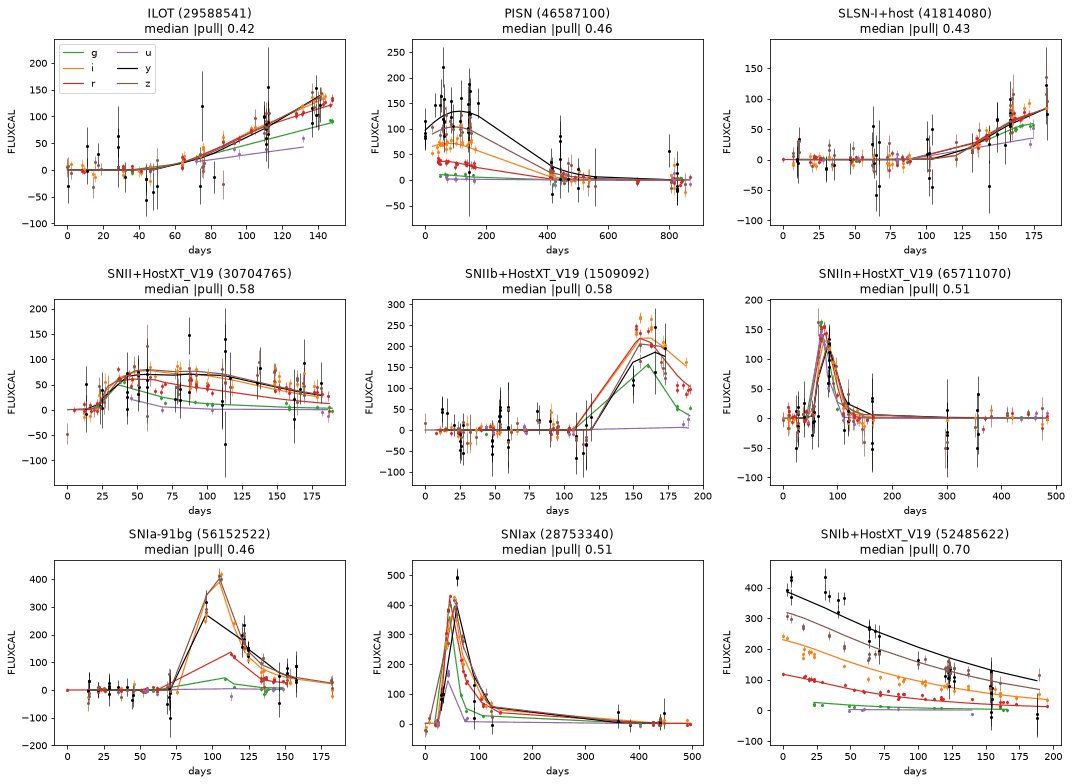

In [9]:
BAND_COLORS = {
    "u": "tab:purple",
    "g": "tab:green",
    "r": "tab:red",
    "i": "tab:orange",
    "z": "tab:brown",
    "y": "k",
}
index_band = {index: name for name, index in model.settings.band_index_map.items()}
t_max = dataset_config["flux_stats"]["t_max"]

# One light curve of at most max_length points per SELDON class (longer ones are windowed).
examples = (
    check[check["SELDON_class"].notna() & (check["n_points"] <= MAX_LENGTH)]
    .groupby("SELDON_class")
    .head(1)
    .index
)
fig, axes = plt.subplots(3, 3, figsize=(15, 11), dpi=72)
for ax, i in zip(axes.flat, examples):
    m = mask[i]
    days = (rerun["time_full"][i, m, 0] - rerun["time_full"][i, m, 0].min()) * t_max
    bands = rerun["band_idx_full"][i, m, 0]
    for b in np.unique(bands):
        name = index_band.get(int(b), str(b))
        color = BAND_COLORS.get(name)
        sel = bands == b
        ax.errorbar(
            days[sel],
            observed[i, m][sel],
            observed_error[i, m][sel],
            fmt=".",
            ms=4,
            elinewidth=0.6,
            color=color,
        )
        ax.plot(days[sel], predicted[i, m][sel], "-", lw=1.2, color=color, label=name)
    row = check.loc[i]
    ax.set_title(f"{row['ELASTICC_class']} ({row['SNID']})\nmedian |pull| {row['median |pull|']:.2f}")
    ax.set_xlabel("days")
    ax.set_ylabel("FLUXCAL")
for ax in axes.flat[len(examples) :]:
    ax.set_visible(False)
axes.flat[0].legend(ncol=2)
fig.tight_layout()
show(fig)

### 3. The class predictions carry information

`class_idx` comes from one posterior sample. For predictions that don't change between runs,
SELDON's energy model is evaluated at the posterior mean `z_mean` with the model's own
`predict_class`, for every object run. Accuracy is over objects in the classes the run was
trained on, mapped to SELDON's classes by the run's `class_mapping`; it should be well above both
the accuracy of always guessing the most common class and that of a random guess with the same
class frequencies (the predictions shuffled between objects). The balanced accuracy is the mean
over classes of the fraction of each class predicted correctly, so it isn't dominated by the
classes with the most objects.

These are SELDON's *training* light curves, so the accuracy is not a measure of how well it
generalizes.

In [10]:
probs = []
with torch.no_grad():
    for start in range(0, len(frame), 65536):
        rows = frame["row"].to_numpy()[start : start + 65536]
        z_mean = torch.as_tensor(outputs["z_mean"][rows], device=device)
        probs.append(model.model.predict_class(z_mean, probs=True).cpu().numpy())
probs = np.concatenate(probs)

frame["predicted_at_mean"] = [
    CLASS_NAMES[i] if i < len(CLASS_NAMES) else f"index {i}" for i in probs.argmax(1)
]
frame["p_max"] = probs.max(1)
known = frame[frame["SELDON_class"].notna()]
truth = known["SELDON_class"].to_numpy()
accuracy = {
    "from a posterior sample (class_idx)": (known["predicted"].to_numpy() == truth).mean(),
    "at the posterior mean": (known["predicted_at_mean"].to_numpy() == truth).mean(),
    "at the posterior mean, balanced": known.assign(hit=known["predicted_at_mean"] == known["SELDON_class"])
    .groupby("SELDON_class")["hit"]
    .mean()
    .mean(),
    "always the most common class": known["SELDON_class"].value_counts(normalize=True).iloc[0],
    "predictions shuffled between objects": (
        np.random.default_rng(SEED).permutation(known["predicted_at_mean"].to_numpy()) == truth
    ).mean(),
}
print(f"Accuracy over the {len(known):,} objects in classes SELDON was trained on:")
for name, value in accuracy.items():
    print(f"  {name:40s} {value:.3f}")
assert accuracy["at the posterior mean"] > 2 * max(
    accuracy["always the most common class"],
    accuracy["predictions shuffled between objects"],
)
print("PASS  well above chance")

Accuracy over the 104,874 objects in classes SELDON was trained on:
  from a posterior sample (class_idx)      0.831
  at the posterior mean                    0.840
  at the posterior mean, balanced          0.805
  always the most common class             0.321
  predictions shuffled between objects     0.200
PASS  well above chance


Rows are the true SELDON class of each object (from its ELAsTiCC class), columns the class
predicted at the posterior mean; each row is normalized to 1.

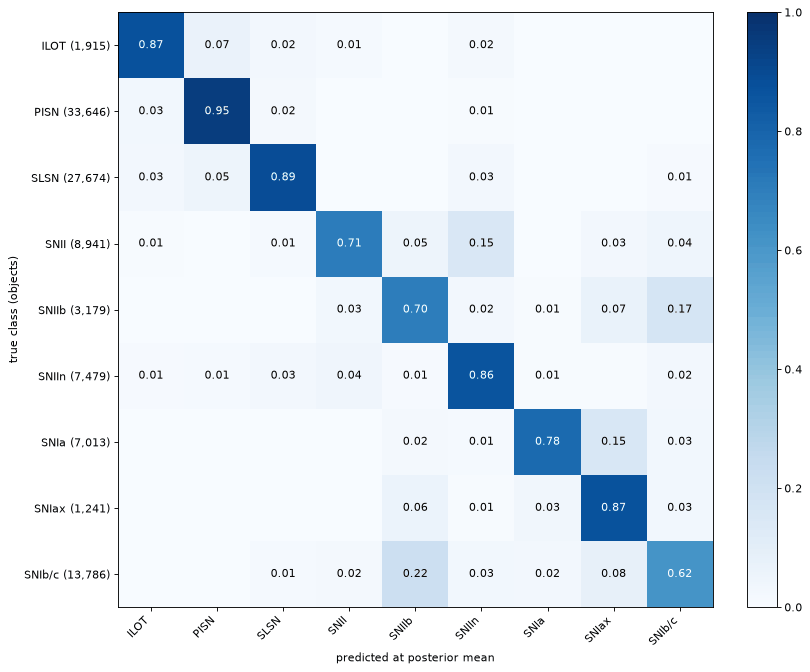

In [11]:
confusion = pd.crosstab(known["SELDON_class"], known["predicted_at_mean"], normalize="index")
confusion = confusion.reindex(
    index=[c for c in CLASS_NAMES if c in confusion.index],
    columns=CLASS_NAMES,
    fill_value=0.0,
)
fig, ax = plt.subplots(figsize=(10, 8.5))
image = ax.imshow(confusion.to_numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(confusion.columns)), confusion.columns, rotation=45, ha="right")
ax.set_yticks(
    range(len(confusion.index)),
    [f"{c} ({(truth == c).sum():,})" for c in confusion.index],
)
for (i, j), value in np.ndenumerate(confusion.to_numpy()):
    if value >= 0.005:
        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value > 0.5 else "black",
        )
ax.set_xlabel("predicted at posterior mean")
ax.set_ylabel("true class (objects)")
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
show(fig)

### Classes SELDON was not trained on

The other ELAsTiCC classes (periodic and stochastic variables, AGN, microlensing, TDEs, ...)
still go through the model, which must call each one of its own classes. How far their
posteriors sit from the prior (the `elbo` output, a KL divergence; all objects) and how well they
are reconstructed (check sample) are two ways to tell them apart from the classes the model knows.

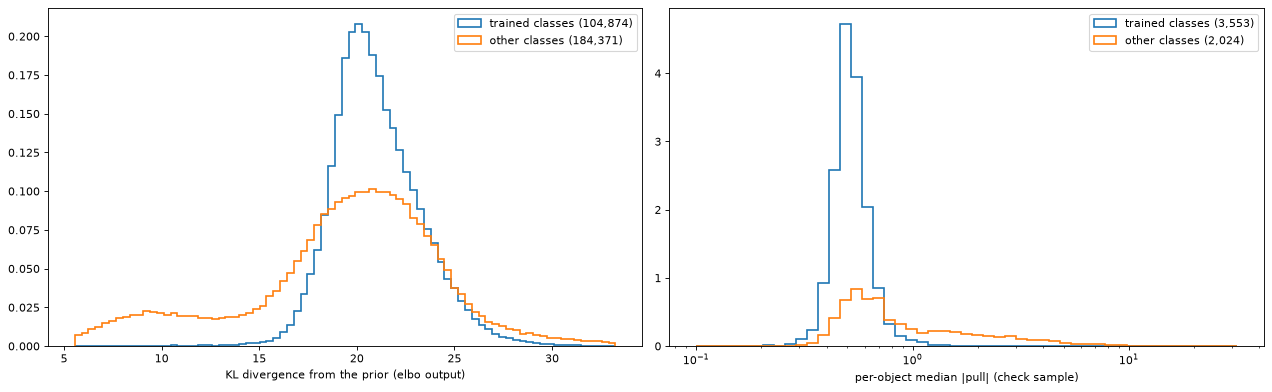

,objects,median_elbo,most_common_prediction
ELASTICC_class,,,
CART,587,20.384384,SNIIn
CLAGN,63566,17.845146,SLSN
Cepheid,17543,22.795828,SNIIn
EB,34790,18.452179,SLSN
RRL,19509,22.529030,ILOT
TDE,7672,19.497017,SNIIn
d-Sct,28740,22.098320,ILOT
dwarf-nova,24,11.688143,SNIb/c
uLens-Binary,2423,22.905602,SLSN


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
trained = frame["SELDON_class"].notna()
low, high = np.nanpercentile(frame["elbo"], [0.5, 99.5])
bins = np.linspace(low, high, 80)
for label, values in [
    ("trained classes", frame.loc[trained, "elbo"]),
    ("other classes", frame.loc[~trained, "elbo"]),
]:
    axes[0].hist(
        values,
        bins=bins,
        histtype="step",
        lw=1.5,
        density=True,
        label=f"{label} ({len(values):,})",
    )
axes[0].set_xlabel("KL divergence from the prior (elbo output)")
axes[0].legend()

check_trained = check["SELDON_class"].notna()
bins = np.logspace(-1, 1.5, 50)
for label, values in [
    ("trained classes", check.loc[check_trained, "median |pull|"]),
    ("other classes", check.loc[~check_trained, "median |pull|"]),
]:
    axes[1].hist(
        values,
        bins=bins,
        histtype="step",
        lw=1.5,
        density=True,
        label=f"{label} ({len(values):,})",
    )
axes[1].set_xscale("log")
axes[1].set_xlabel("per-object median |pull| (check sample)")
axes[1].legend()
fig.tight_layout()
show(fig)

(
    frame[~trained]
    .groupby("ELASTICC_class")
    .agg(
        objects=("SNID", "size"),
        median_elbo=("elbo", "median"),
        most_common_prediction=(
            "predicted_at_mean",
            lambda s: s.value_counts().index[0],
        ),
    )
)

### 4. SELDON run directly, without Hyrax, gives the same results

This reruns the check sample through SELDON alone, the way SELDON's own tutorial notebook loads a
model and prepares light curves, with no `hyrax` or `hyrax_seldon` code involved, and compares
`z_mean`, `z_sigma`, `reconstructed` and `error` with what Hyrax saved for the same objects. It
catches results attached to the wrong object, as well as any difference in how `hyrax_seldon`
prepares the light curves.

Two differences are expected, and are shown rather than hidden:

- **Light curves of more than `max_length` points.** The tutorial encodes every point; SELDON's
  data loader, which `hyrax_seldon` uses, encodes a random window of 256. These are compared
  separately.
- **Time precision.** Both round times to float32 before taking the time since the first
  point, at different stages: SELDON's data loader rounds MJDs (about 60,000, so to steps of about
  0.004 days), the tutorial rounds MJD / `t_max` (to steps of about 0.005 days). The model was
  trained with the loader's rounding. So the tutorial's preparation is run three ways: as written,
  with exact times, and with the loader's time arithmetic. The last must reproduce Hyrax's outputs;
  the other two show how much the rounding changes them.

In [13]:
import pytorch_lightning as pl
import seldon_core  # SELDON's package (also importable as TAE)
import torch.backends.cudnn as cudnn
from omegaconf import OmegaConf
from seldon_core.datasets.dataset_factory import get_module as get_dataset
from seldon_core.experiments.factory import get_module as get_experiment
from seldon_core.models.factory import MODULES, get_module, registry


def load_seldon(model_folder, seldon_base_path, hparams_copy, device="cuda"):
    # The tutorial's load_seldon. Its only change to the run config is to point the filter
    # transmission files at this SELDON install; it builds SELDON's experiment, with its data
    # module (setup_from_data=False: the run's statistics, no training files read), and loads the
    # Lightning checkpoint with the experiment's own load_from_checkpoint.
    hparams_file = model_folder / "hparams.yaml"
    with open(hparams_file) as f, open(hparams_copy, "w") as out:
        for line in f:
            if "/projects/ncsa/caps/skai/software/Transient-Foundation-Model/" in line:
                pre, post = line.split(":")
                post = str(seldon_base_path / "/".join(Path(post.strip()).parts[-3:]))
                line = ": ".join((pre, post)) + "\n"
            out.write(line)
    (checkpoint_file,) = model_folder.glob("checkpoints/epoch*")
    config = OmegaConf.to_container(OmegaConf.load(hparams_copy))
    config["dataset"]["config"]["augmentations"] = ["FullSample"]
    config["dataset"]["config"]["setup_from_data"] = False

    pl.seed_everything(config["logging_params"]["manual_seed"])
    cudnn.deterministic = True
    cudnn.benchmark = False

    seldon_model = get_module(config["model_params"]["name"], config["model_params"]["config"])
    data = get_dataset(config["dataset"]["name"], config["dataset"]["config"])
    data.band_array = []
    data.setup()
    experiment = get_experiment(
        config["exp_params"]["name"],
        {"model": seldon_model, "data": data, **config["exp_params"]["config"]},
    )
    registry["checkpoint"] = experiment.__class__.load_from_checkpoint
    MODULES.update(registry)
    experiment = get_module(
        "checkpoint",
        dict(
            weights_only=True,
            strict=False,
            checkpoint_path=str(checkpoint_file),
            model=seldon_model,
            data=experiment.data,
            **config["exp_params"]["config"],
        ),
    )
    # The tutorial loads with strict=False; make sure every weight was actually loaded.
    saved = torch.load(checkpoint_file, map_location="cpu", weights_only=True)["state_dict"]
    assert set(saved) == set(experiment.state_dict()), "checkpoint and model weights differ"
    return experiment.eval().to(device)


def light_curve_to_seldon(
    experiment,
    mjd,
    flux,
    flux_err,
    detection_flag,
    band,
    times="tutorial",
    device="cuda",
):
    # The tutorial's light_curve_to_seldon, evaluating the decoder at the observed points.
    # ELAsTiCC's FLUXCAL already has SELDON's zero point (27.5), so the flux is not rescaled.
    # `times` picks how times relative to the first point are computed (see the text above):
    t_scale = experiment.data.dataset.flux_stats["t_max"]
    if times == "tutorial":  # as the tutorial: MJD / t_max (~3000) to float32, then subtract
        order = np.argsort(mjd)
        t0 = mjd[order][0] / t_scale
        t_seldon = torch.from_numpy(mjd[order] / t_scale).to(torch.float32).to(device) - t0
    elif times == "loader":  # as SELDON's data loader: MJD to float32, subtract, divide by t_max
        mjd = mjd.astype(np.float32)
        order = np.argsort(mjd)
        t_seldon = torch.from_numpy((mjd[order] - mjd[order][0]) / np.float32(t_scale)).to(device)
    else:  # "exact": subtract in float64, then convert
        order = np.argsort(mjd)
        t_seldon = torch.from_numpy((mjd[order] - mjd[order][0]) / t_scale).to(torch.float32).to(device)
    flux_seldon, flux_err_seldon = experiment.data.dataset.transform(
        *[torch.from_numpy(f[order]).to(device).to(torch.float32) for f in (flux, flux_err)]
    )
    detection_seldon = torch.from_numpy(detection_flag[order]).to(torch.float32).to(device)
    band_seldon = torch.tensor([experiment.data.band_index_map[b] for b in band[order]], device=device)
    return {
        "x_input": torch.stack([t_seldon, flux_seldon, flux_err_seldon, detection_seldon], dim=1),
        "time_full": t_seldon.unsqueeze(-1),
        "band_idx": band_seldon.unsqueeze(-1),
        "band_idx_full": band_seldon.unsqueeze(-1),
        "pad_mask_part": torch.ones_like(flux_seldon, dtype=torch.bool),
        "class_name": "SNIa",  # unused by the outputs compared here; the experiment requires one
    }


def stack_seldon_inputs(*seldon_inputs):
    # The tutorial's stack_seldon_inputs: zero-pad every light curve to the longest and stack.
    def pad(tensor, length):
        return torch.nn.functional.pad(tensor, [0, 0] * (tensor.dim() - 1) + [0, length - tensor.shape[0]])

    length = max(inputs["x_input"].shape[0] for inputs in seldon_inputs)
    return {
        key: torch.stack([pad(inputs[key], length) for inputs in seldon_inputs])
        if isinstance(seldon_inputs[0][key], torch.Tensor)
        else [inputs[key] for inputs in seldon_inputs]
        for key in seldon_inputs[0]
    }


def tutorial_inputs(light_curve, times):
    # One ELAsTiCC light curve as the tutorial's inputs. Saturated points (PHOTFLAG 1024) are
    # dropped, and a point is a detection when PHOTFLAG flags it as one (4096 or 2048), as in
    # SELDON's training data. ELAsTiCC writes the y band as "Y"; SELDON's bands are lower case.
    flags = np.asarray(light_curve["PHOTFLAG"]).astype(np.int64)
    keep = (flags & 1024) == 0
    band = np.array([b.lower() if len(b) == 1 else b for b in np.asarray(light_curve["BAND"])[keep]])
    return light_curve_to_seldon(
        experiment,
        np.asarray(light_curve["MJD"], dtype=np.float64)[keep],
        np.asarray(light_curve["FLUXCAL"], dtype=np.float64)[keep],
        np.asarray(light_curve["FLUXCALERR"], dtype=np.float64)[keep],
        (flags[keep] & 6144) != 0,
        band,
        times=times,
        device=device,
    )


def run_tutorial(times, batch_size=256):
    # Run the check sample through the experiment; return each output per object, padded to
    # max_length points like Hyrax's (the longest light curves are cut to max_length here).
    keys = ["z_mean", "z_sigma", "reconstructed", "error"]
    collected = {key: [] for key in keys}
    for start in range(0, len(check), batch_size):
        batch = [tutorial_inputs(lc, times) for _, lc in check.iloc[start : start + batch_size].iterrows()]
        # Eagerly: SELDON's factory keeps its torch.compile() calls, and compiling for each of
        # this cell's batch shapes would take longer than running them.
        with torch.no_grad(), torch.compiler.set_stance("force_eager"):
            out = experiment(stack_seldon_inputs(*batch))
        for key in keys:
            value = out[key].float().cpu().numpy()
            if value.ndim == 3:
                value = np.pad(value, ((0, 0), (0, max(0, MAX_LENGTH - value.shape[1])), (0, 0)))[
                    :, :MAX_LENGTH
                ]
            collected[key].append(value)
    return {key: np.concatenate(value) for key, value in collected.items()}


def max_difference(direct, key):
    # Largest |direct - hyrax| per object; per-point outputs over Hyrax's real points only.
    saved = check_outputs[key] if key in check_outputs else outputs[key][check["row"].to_numpy()]
    difference = np.abs(direct[key] - saved).reshape(len(check), -1)
    if key in ("reconstructed", "error"):
        difference = np.where(check_outputs["pad_mask_full"], difference, 0)
    return difference.max(axis=1)


seldon_base_path = Path(seldon_core.__file__).resolve().parent.parent  # holds TAE/data/*.dat
experiment = load_seldon(SELDON_RUN_DIR, seldon_base_path, WORK_DIR / "hparams_tutorial.yaml", device)

long = check["n_points"].to_numpy() > MAX_LENGTH
print(f"{(~long).sum():,} light curves of at most {MAX_LENGTH} points, {long.sum():,} longer\n")
COMPARED = ["z_mean", "z_sigma", "reconstructed", "error"]
TIMES = {
    "tutorial": "times as the tutorial computes them",
    "exact": "exact times",
    "loader": "times as SELDON's data loader computes them",
}
direct, rows = {}, []
for times, label in TIMES.items():
    direct[times] = run_tutorial(times)
    for key in COMPARED:
        d = max_difference(direct[times], key)[~long]
        rows.append((label, key, np.median(d), np.percentile(d, 99), d.max()))
table = pd.DataFrame(
    rows,
    columns=["SELDON run directly, with", "output", "median", "99th percentile", "max"],
)
print(
    f"max |direct - hyrax| per object, over the {(~long).sum():,} light curves of at most {MAX_LENGTH} points:"
)
print(table.to_string(index=False, float_format="{:.1e}".format))

d = max_difference(direct["loader"], "z_mean")[long]
print(
    f"\nLonger light curves (all points vs. a window), z_mean: median {np.median(d):.2f}, max {d.max():.2f}"
)

# Float32 roundoff: Hyrax pads each batch to max_length points, the tutorial to its longest light
# curve, and the tutorial transforms fluxes with torch rather than numpy.
TOLERANCE = {"z_mean": 1e-3, "z_sigma": 1e-3, "reconstructed": 1e-2, "error": 1e-2}
worst = {key: max_difference(direct["loader"], key)[~long].max() for key in COMPARED}
assert all(worst[key] < TOLERANCE[key] for key in COMPARED), worst
print(
    f"PASS  with the loader's times, all {(~long).sum():,} light curves of at most {MAX_LENGTH} points match Hyrax"
)

[rank: 0] Seed set to 42


Log Flux is True, max log: 5.367475894613145


/u/mtauraso/hyrax-seldon-workspace/seldon/TAE/datasets/lightcurve_dataloader2.py:302: UserWarning: Length of split at index 0 is 0. This might result in an empty dataset.
  self.train_data, self.val_data, self.test_data = random_split(
/u/mtauraso/hyrax-seldon-workspace/seldon/TAE/datasets/lightcurve_dataloader2.py:302: UserWarning: Length of split at index 1 is 0. This might result in an empty dataset.
  self.train_data, self.val_data, self.test_data = random_split(
Initialized SELDON with 9 classes and hidden dim of 256


Initialized SELDON with 9 classes and hidden dim of 256


4,503 light curves of at most 256 points, 1,074 longer



max |direct - hyrax| per object, over the 4,503 light curves of at most 256 points:
                  SELDON run directly, with        output  median  99th percentile     max
        times as the tutorial computes them        z_mean 4.5e-04          2.2e-02 2.1e-01
        times as the tutorial computes them       z_sigma 1.4e-05          1.3e-03 3.2e-02
        times as the tutorial computes them reconstructed 9.7e-04          2.4e-01 1.4e+00
        times as the tutorial computes them         error 1.3e-03          2.0e-01 4.0e+00
                                exact times        z_mean 4.4e-04          2.2e-02 2.1e-01
                                exact times       z_sigma 1.4e-05          1.3e-03 3.2e-02
                                exact times reconstructed 8.6e-04          2.4e-01 1.4e+00
                                exact times         error 1.2e-03          2.0e-01 4.0e+00
times as SELDON's data loader computes them        z_mean 1.4e-06          2.2e-05 6.0e-05
times 